## Análisis: Hallazgos

Principales hallazgos, organizados por los enfoques (PQ1, PQ2, PQ3)

### Utilidades

In [1]:
NOTEBOOK = "b_hallazgos"
%run ../funciones.ipynb
%run funciones.ipynb

In [2]:
spark = crear_spark(NOTEBOOK)
verificar_cluster(spark)

Master        : spark://spark-master:7077
Executors     : 2
Cores totales : 2
Memoria driver: 2.0 GB
UI del job    : http://localhost:4040


---
### **1. PQ1: Concentración y cautividad**

¿Qué entidades dependen de pocos proveedores y qué proveedores concentran el gasto de muchas entidades?

#### a. ¿Quiénes son cautivas y de quién dependen?

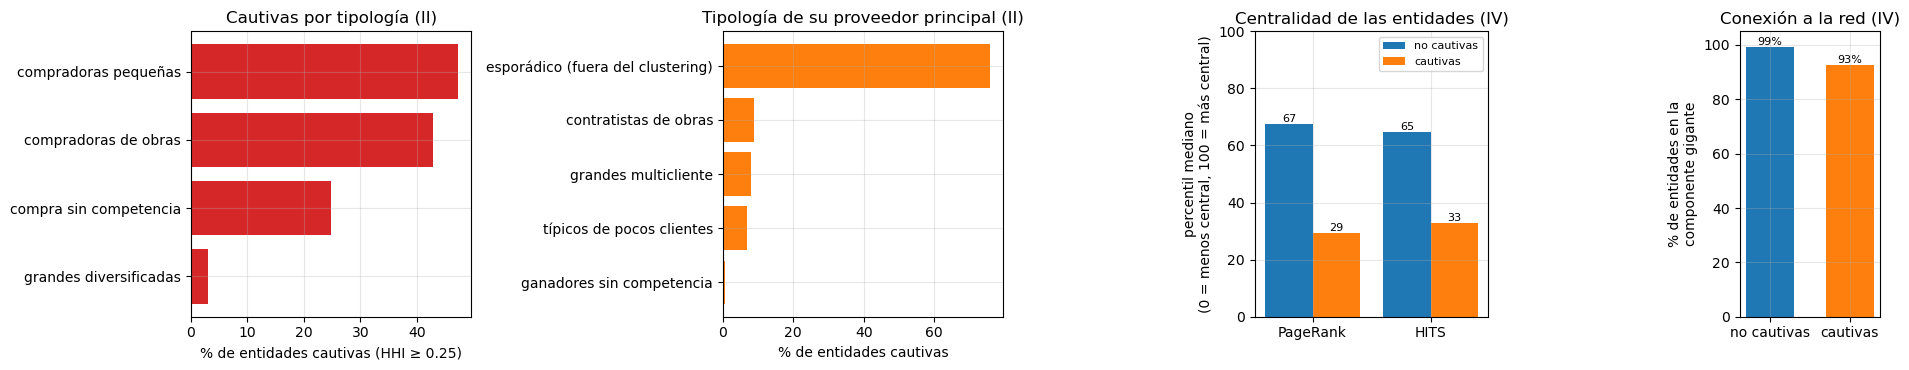

,umbral_hhi,entidades,pct_entidades,postor_unico_med,directa_med,procesos_med
0,0.25,807,29.9,0.0,0.0,12.0
1,0.40,332,12.3,0.0,0.0,11.0
2,0.50,191,7.1,0.0,0.0,10.0


In [3]:
cau_tip = tabla("02_Clustering", "e_analisis", "cautivas_por_tipologia")
atienden = tabla("02_Clustering", "e_analisis", "atienden_cautivas")
cau_umbral = tabla("02_Clustering", "e_analisis", "cautivas_umbral")
cau_pr = tabla("04_PageRank", "d_analisis", "cautividad").set_index("cautiva")
contraste = tabla("04_PageRank", "d_analisis", "contraste_monto").set_index("grupo")
fig, ax = plt.subplots(1, 4, figsize=(19, 3.8), gridspec_kw={"width_ratios": [1.2, 1.2, 1, .6]})
c_ = cau_tip.sort_values("pct_cautivas")
ax[0].barh(c_.tipologia, c_.pct_cautivas, color="tab:red"); ax[0].set(xlabel="% de entidades cautivas (HHI ≥ 0.25)", title="Cautivas por tipología (II)")
a_ = atienden.sort_values("pct")
ax[1].barh(a_.tipologia_proveedor, a_.pct, color="tab:orange"); ax[1].set(xlabel="% de entidades cautivas", title="Tipología de su proveedor principal (II)")
x_ = np.arange(2)
for k_, (lbl, col) in enumerate([("no cautivas", 0), ("cautivas", 1)]):
    r = cau_pr.loc[col]
    b = ax[2].bar(x_ + (k_ - .5) * .4, [100 * r.pct_pr_med, 100 * r.pct_hits_med], .4, label=lbl)
    ax[2].bar_label(b, fmt="%.0f", fontsize=8)
    b = ax[3].bar(k_, r.pct_en_gigante, .6, color=b[0].get_facecolor())
    ax[3].bar_label(b, fmt="%.0f%%", fontsize=8)
ax[2].set_xticks(x_); ax[2].set_xticklabels(["PageRank", "HITS"])
ax[2].set(ylim=(0, 100), ylabel="percentil mediano\n(0 = menos central, 100 = más central)", title="Centralidad de las entidades (IV)"); ax[2].legend(fontsize=8)
ax[3].set_xticks([0, 1]); ax[3].set_xticklabels(["no cautivas", "cautivas"])
ax[3].set(ylim=(0, 105), ylabel="% de entidades en la\ncomponente gigante", title="Conexión a la red (IV)")
mostrar_fig("pq1_cautivas")
display(cau_umbral)

- **30% de las entidades son cautivas** (HHI ≥ 0.25)

- **Compradoras pequeñas** (47%) y **de obras** (43%), y casi ninguna grande diversificada (3%)

- **Dependen de proveedores esporádicos:** 76% cautivas tiene como proveedor principal a uno fuera del clustering

- **Son periféricas:** percentil mediano de PageRank 0.29 vs 0.67 de las no cautivas, y 8 proveedores vs 35

#### b. ¿Falta de alternativas?

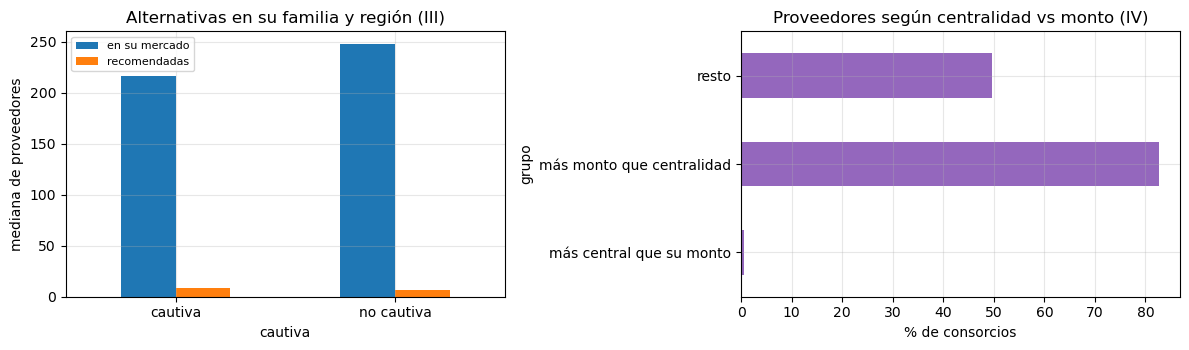

,entidades,hhi_mediano,proveedores_mediana,alt_mercado_mediana,pct_sin_alt_mercado,evaluadas,alt_recomendadas_mediana,pct_sin_alt_recomendada
cautiva,,,,,,,,
cautiva,964,0.397,7.0,217.0,0.3,494,9.0,4.9
no cautiva,1882,0.101,35.0,248.0,0.8,1614,7.0,10.4


In [4]:
alt = tabla("03_Recomend", "f_analisis", "pq1_alternativas").set_index("cautiva")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
alt[["alt_mercado_mediana", "alt_recomendadas_mediana"]].plot.bar(ax=ax[0], rot=0)
ax[0].set(ylabel="mediana de proveedores", title="Alternativas en su familia y región (III)"); ax[0].legend(["en su mercado", "recomendadas"], fontsize=8)
contraste.pct_consorcio.plot.barh(ax=ax[1], color="tab:purple")
ax[1].set(xlabel="% de consorcios", title="Proveedores según centralidad vs monto (IV)")
mostrar_fig("pq1_alternativas")
alt

- **No falta oferta:** las cautivas tienen una mediana de **217 proveedores** en su familia y región (248 las no cautivas)

- **El dinero concentrado está en consorcios:** 83% de los proveedores con "más monto que centralidad" son consorcios 

#### c. Respuesta

- **La cautividad es local:** entidades chicas o de obras atadas a un consorcio armado para una obra

- **Los proveedores que concentran el gasto de muchas entidades** son los grandes multicliente 

- 50% del monto de proveedores es top de PageRank, y **no** son los que atienden a las cautivas

---
### **2. PQ2: Mercados y competencia**

¿Qué mercados emergen de la co-participación? ¿Son regionales o por rubro? ¿Qué grupos compiten siempre entre sí?

#### a. Rubro o región

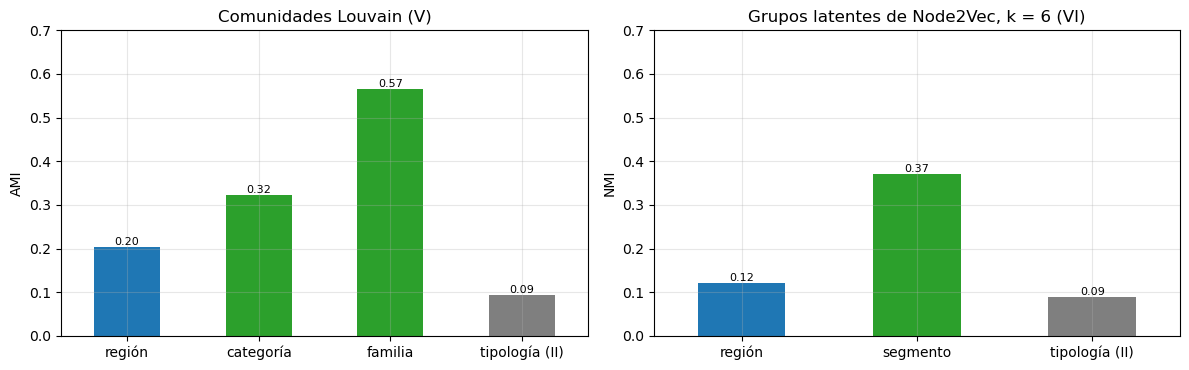

In [5]:
ex = tabla("05_Comunidad", "e_analisis", "explica")
ex = ex[(ex.particion == "louvain") & (ex.sin_dato == "excluido")].set_index("atributo")
cv = tabla("06_Representacion", "c_proyeccion", "convergencia")
cv = cv[cv.config == "p1_q1"].set_index("referencia")
v5 = pd.Series({"región": ex.loc["region_dom", "ami"], "categoría": ex.loc["categoria_dom", "ami"], "familia": ex.loc["familia_dom", "ami"],
                "tipología (II)": ex.loc["tipologia", "ami"]})
v6 = pd.Series({"región": cv.loc["región", "nmi"], "segmento": cv.loc["segmento", "nmi"], "tipología (II)": cv.loc["tipología (KMeans II)", "nmi"]})
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
v5.plot.bar(ax=ax[0], rot=0, color=["tab:blue", "tab:green", "tab:green", "tab:gray"]); ax[0].set(ylim=(0, .7), ylabel="AMI", title="Comunidades Louvain (V)")
v6.plot.bar(ax=ax[1], rot=0, color=["tab:blue", "tab:green", "tab:gray"]); ax[1].set(ylim=(0, .7), ylabel="NMI", title="Grupos latentes de Node2Vec, k = 6 (VI)")
for a_ in ax:
    a_.bar_label(a_.containers[0], fmt="%.2f", fontsize=8)
mostrar_fig("pq2_rubro_region")

- **Métodos independientes dan lo mismo:** las comunidades y los grupos latentes 

- Se explican más por **rubro** (verde) que por **región** (azul)

- **V:** familia AMI 0.57 y categoría 0.32 vs región 0.20; **VI:** segmento NMI 0.37 vs región 0.12

#### b. Mercados y grupos cerrados

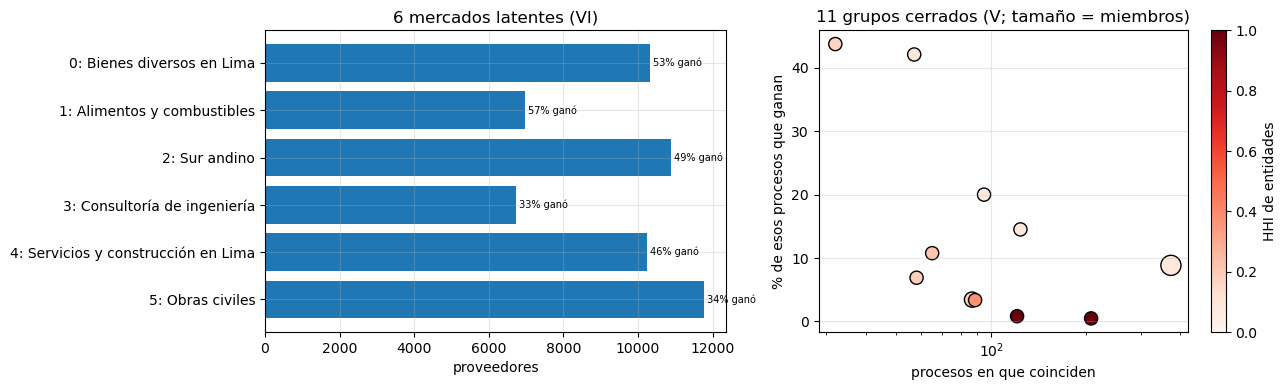

In [6]:
pl = tabla("06_Representacion", "c_proyeccion", "perfiles_latentes")
gc = tabla("05_Comunidad", "e_analisis", "grupos_cerrados")
fig, ax = plt.subplots(1, 2, figsize=(13, 4))

def nombre_mercado(r):
    seg, reg = str(r.segmento), str(r.region)
    pct_seg = float(seg.split("(")[1].rstrip("%)")) if "(" in seg else 0
    if seg.startswith("81"): return "Consultoría de ingeniería"
    if seg.startswith(("50", "15")): return "Alimentos y combustibles"
    if reg.startswith("CUSCO"): return "Sur andino"
    if seg.startswith("72") and pct_seg >= 80: return "Obras civiles"
    if seg.startswith("72"): return "Servicios y construcción en Lima"
    return "Bienes diversos en Lima"

et = [f"{r.grupo}: {nombre_mercado(r)}" for r in pl.itertuples()]
ax[0].barh(et, pl.proveedores, color="tab:blue"); ax[0].invert_yaxis()
for yy, (p, g) in enumerate(zip(pl.proveedores, pl.pct_gano)):
    ax[0].text(p, yy, f" {100 * g:.0f}% ganó", va="center", fontsize=7)
ax[0].set(xlabel="proveedores", title="6 mercados latentes (VI)")
sc = ax[1].scatter(gc.procesos_juntos, 100 * gc.tasa_victoria_juntos, s=30 * gc.tamano, c=gc.hhi_entidades, cmap="Reds", edgecolors="k", vmin=0, vmax=1)
plt.colorbar(sc, ax=ax[1], label="HHI de entidades")
ax[1].set(xscale="log", xlabel="procesos en que coinciden", ylabel="% de esos procesos que ganan", title="11 grupos cerrados (V; tamaño = miembros)")
mostrar_fig("pq2_mercados")

- **6 mercados** en todo el grafo (57k proveedores)

- Obras civiles, consultoría de ingeniería, sur andino, servicios en Lima, bienes diversos en Lima, alimentos y combustibles

- **41 comunidades** en el núcleo (7k competidores recurrentes) que se anidan en esos 6 mercados (anidamiento 0.83)

- **11 grupos cerrados** (3-7 proveedores densos y aislados); los que coinciden en más de 100 procesos 

- Casi no ganan son **señales para revisar**, no conclusiones

#### c. Respuesta

- **Los mercados son por rubro primero y por región después:** bienes, servicios y obras casi no se mezclan

- Dentro del rubro, la región separa (el sur andino es el único mercado definido por geografía)

- **Grupos que compiten siempre entre sí:** existen (11 grupos cerrados), pero son pocos

- En su mayoría compatibles con mercados chicos especializados

---
### **3. PQ3: Sustitutos y afinidades**

Para una entidad, ¿qué proveedores son alternativas y qué relaciones son atípicas?

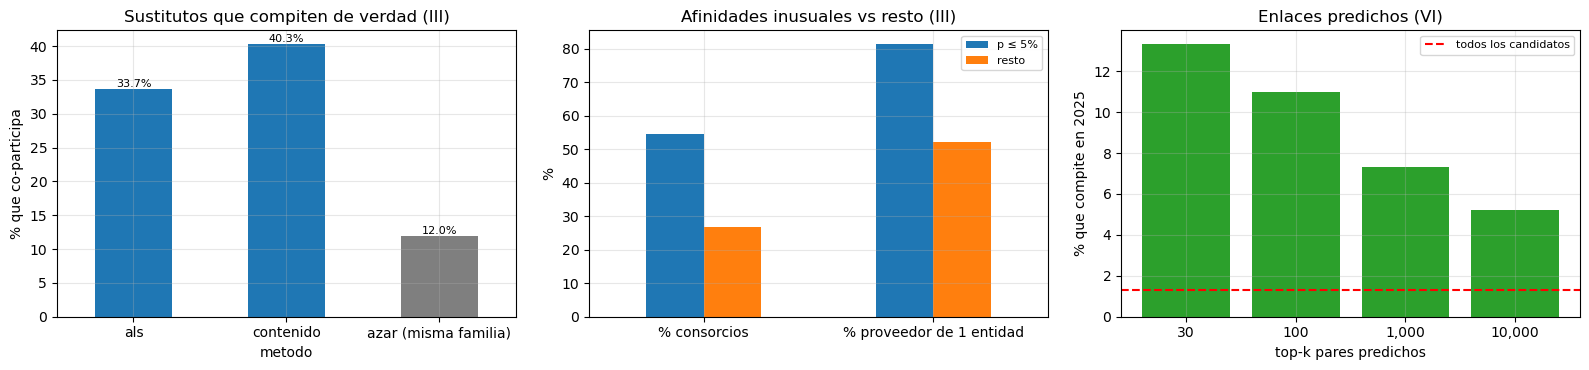

In [7]:
sus = tabla("03_Recomend", "f_analisis", "sustitutos_resumen").set_index("metodo")
af = tabla("03_Recomend", "f_analisis", "afinidades_inusuales").set_index("grupo")
pt = tabla("06_Representacion", "d_enlaces", "precision_top")
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
sus.pct_coparticipan.loc[["als", "contenido", "azar (misma familia)"]].plot.bar(ax=ax[0], rot=0, color=["tab:blue", "tab:blue", "tab:gray"])
ax[0].bar_label(ax[0].containers[0], fmt="%.1f%%", fontsize=8); ax[0].set(ylabel="% que co-participa", title="Sustitutos que compiten de verdad (III)")
af.loc[["p ≤ 5%", "resto"], ["pct_consorcio", "pct_prov_una_entidad"]].T.plot.bar(ax=ax[1], rot=0)
ax[1].set_xticklabels(["% consorcios", "% proveedor de 1 entidad"]); ax[1].set(ylabel="%", title="Afinidades inusuales vs resto (III)"); ax[1].legend(fontsize=8)
p_ = pt.iloc[:-1]
ax[2].bar(p_.top.map("{:,}".format), p_["% aparece en 2025"], color="tab:green")
ax[2].axhline(pt["% aparece en 2025"].iloc[-1], color="red", ls="--", label="todos los candidatos")
ax[2].set(xlabel="top-k pares predichos", ylabel="% que compite en 2025", title="Enlaces predichos (VI)"); ax[2].legend(fontsize=8)
mostrar_fig("pq3")

- **Sustitutos reales:** el 34% (ALS) y el 40% (contenido) de los sustitutos de una familia ya compiten entre sí en procesos

- **Afinidades inusuales** (5% de relaciones con menor puntaje): 55% consorcios y 81% proveedores de una sola entidad

- **Enlaces predichos:** el top 100 se concreta en 2025 en un 9%, ×7 sobre la base

- El top son distribuidores de **medicamentos e insumos médicos de Lima**

#### a. Respuesta

- **Alternativas:** existen y son verificables; los sustitutos de ALS y contenido son competidores reales

- Los enlaces predichos señalan proveedores que el mercado ubica en el mismo lugar

- **Afinidades atípicas:** sobre todo consorcios de una sola obra; lo atípico es su **unicidad**, no una conducta

---
### **4. Resumen de respuestas**

In [8]:
respuestas = pd.DataFrame([
    {"pregunta": "PQ1: Concentración y cautividad",
     "respuesta": "30% de entidades cautivas, chicas o de obras, atadas a consorcios de un solo proceso; no falta oferta (217 alternativas) y no las capturan los proveedores centrales",
     "evidencia": "KMeans + HHI (II), PageRank/HITS (IV), alternativas del híbrido (III)"},
    {"pregunta": "PQ2: Mercados y competencia",
     "respuesta": "Mercados por rubro y luego región: 6 mercados latentes que agrupan 41 comunidades; 11 grupos cerrados como señales",
     "evidencia": "Louvain, BigCLAM, LPA (V); Node2Vec + KMeans (VI)"},
    {"pregunta": "PQ3: Sustitutos y afinidades",
     "respuesta": "Sustitutos que compiten de verdad (34-40% vs 12%); afinidades inusuales = consorcios de una obra; pares afines en salud (lift ×7)",
     "evidencia": "ALS, contenido, híbrido (III); predicción de enlaces (VI)"}])
respuestas

,pregunta,respuesta,evidencia
0,PQ1: Concentración y cautividad,"30% de entidades cautivas, chicas o de obras, atadas a consorcios de un solo...","KMeans + HHI (II), PageRank/HITS (IV), alternativas del híbrido (III)"
1,PQ2: Mercados y competencia,Mercados por rubro y luego región: 6 mercados latentes que agrupan 41 comuni...,"Louvain, BigCLAM, LPA (V); Node2Vec + KMeans (VI)"
2,PQ3: Sustitutos y afinidades,Sustitutos que compiten de verdad (34-40% vs 12%); afinidades inusuales = co...,"ALS, contenido, híbrido (III); predicción de enlaces (VI)"


---
### **5. Escritura de resultados**

In [9]:
escritos = guardar_tablas({"respuestas": respuestas})

Escrito en 07_Analisis/temp/b_hallazgos/: respuestas


#### a. Verificación

In [10]:
verificar_salidas(escritos)

OK: 1 tablas (parquet + json) | 5 figuras: pq1_alternativas, pq1_cautivas, pq2_mercados, pq2_rubro_region, pq3


---
### **6. Cerrar sesión**

In [11]:
spark.stop()